# Step 1 – Dataset Understanding and Exploratory Data Analysis (EDA)
**Code used:** `pathsnap/data_loading.py` (reading the raw files), `pathsnap/geometry.py` (distances).
**Partitions:** `train` (80 trips) and `student_test` (10 trips). The evaluator partition is never used.

Contents
1. Dataset inventory (trips, files, rows)
2. GPS quality: sampling interval, gaps, missing values, trip size
3. Geographic extent, and why we need metres instead of degrees
4. Road network: size, connectivity, isolated nodes, components
5. Reference route: structure and continuity
6. Folium map of one raw trip
7. Data-quality issues found

In [1]:
import os, sys, time, json, warnings
sys.path.insert(0, os.path.abspath('..')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 110
from pathsnap.data_loading import list_trips, load_trip, DATA_ROOT
print('data folder:', DATA_ROOT)
import networkx as nx, folium
from pathsnap.geometry import haversine, LocalProjection
OUT = os.path.abspath('../results/01_eda'); MAPS = os.path.abspath('../results/maps')
os.makedirs(OUT, exist_ok=True); os.makedirs(MAPS, exist_ok=True)

data folder: C:\Users\amanp\Downloads\ML_Hackathon\StudentFolder\Student folder


## 1. Dataset inventory

In [2]:
rows = []
for part in ['train', 'student_test']:
    for tid in list_trips(part):
        folder = os.path.join(DATA_ROOT, part, tid); files = sorted(os.listdir(folder))
        tr = load_trip(part, tid)
        t = tr['track']; dt = np.diff(t['t'].values)
        g = nx.DiGraph(); g.add_nodes_from(range(len(tr['nodes']))); g.add_edges_from(tr['arcs'][['u','v']].values)
        ug = g.to_undirected()
        largest = max(len(c) for c in nx.connected_components(ug))
        route = tr['route']; arcs = tr['arcs'].values
        route_cont = float((arcs[route[:-1],1] == arcs[route[1:],0]).mean()) if route is not None and len(route) > 1 else np.nan
        path_len = haversine(t.lon.values[:-1], t.lat.values[:-1], t.lon.values[1:], t.lat.values[1:]).sum()
        rows.append(dict(partition=part, trip_id=tid, n_files=len(files),
            size_kb=sum(os.path.getsize(os.path.join(folder, f)) for f in files) / 1024,
            n_gps=len(t), n_nodes=len(tr['nodes']), n_arcs=len(arcs),
            n_route_arcs=len(route) if route is not None else 0,
            missing_vals=int(t.isna().sum().sum()), non_increasing_t=int((dt <= 0).sum()),
            dt_median=np.median(dt), dt_max=dt.max(), pct_dt_1s=100 * (dt == 1).mean(),
            n_gaps_gt10s=int((dt > 10).sum()), duration_min=(t.t.iloc[-1] - t.t.iloc[0]) / 60,
            gps_path_km=path_len / 1000, lon_c=t.lon.mean(), lat_c=t.lat.mean(),
            isolated_nodes=int(sum(1 for n in ug.nodes if ug.degree(n) == 0)),
            components=nx.number_connected_components(ug), largest_comp_frac=largest / len(tr['nodes']),
            route_continuity=route_cont))
inv = pd.DataFrame(rows); inv.to_csv(f'{OUT}/dataset_inventory.csv', index=False)
print(inv.groupby('partition').agg(trips=('trip_id','count'), files=('n_files','sum'),
      gps_points=('n_gps','sum'), median_gps=('n_gps','median'), route_arcs=('n_route_arcs','sum')))
inv.head()

              trips  files  gps_points  median_gps  route_arcs
partition                                                     
student_test     10     40       19160      1420.0        3477
train            80    320      208417      1529.0       31336


,partition,trip_id,n_files,size_kb,n_gps,n_nodes,n_arcs,n_route_arcs,missing_vals,non_increasing_t,...,pct_dt_1s,n_gaps_gt10s,duration_min,gps_path_km,lon_c,lat_c,isolated_nodes,components,largest_comp_frac,route_continuity
0,train,00000001,4,3593.690430,1315,88809,165790,525,0,0,...,98.097412,1,22.616667,50.186184,8.605599,50.088368,0,175,0.977986,1.000000
1,train,00000002,4,541.720703,7243,7936,16139,262,0,0,...,97.445457,41,148.885933,55.872334,11.032568,47.683925,0,14,0.976562,0.996169
2,train,00000003,4,376.042969,821,9138,18028,79,0,0,...,99.634146,0,13.716667,8.420159,37.177362,55.987684,0,42,0.943861,1.000000
3,train,00000004,4,325.490234,1064,7350,15499,320,0,0,...,53.809972,215,86.950000,27.891025,12.424218,52.641499,0,12,0.986939,1.000000
4,train,00000005,4,62.607422,1045,898,1579,105,0,0,...,100.000000,0,17.400000,31.325944,35.503261,49.486068,0,3,0.988864,1.000000


In [3]:
summary = inv.groupby('partition')[['n_gps','duration_min','gps_path_km','dt_median','dt_max','pct_dt_1s',
        'n_gaps_gt10s','missing_vals','non_increasing_t','n_nodes','n_arcs','n_route_arcs',
        'components','isolated_nodes','largest_comp_frac','route_continuity']].describe().T
summary.to_csv(f'{OUT}/summary_stats.csv'); summary.round(3)

partition               student_test     train
n_gps            count        10.000    80.000
                 mean       1916.000  2605.212
                 std        1335.432  3312.345
                 min         262.000   361.000
                 25%         917.750   945.750
...                              ...       ...
route_continuity min           0.997     0.981
                 25%           1.000     1.000
                 50%           1.000     1.000
                 75%           1.000     1.000
                 max           1.000     1.000

[128 rows x 2 columns]

**Reading the table:** no missing values and no out-of-order timestamps. Sampling is nominally 1 Hz,
but some trips have long gaps (`dt_max`). Every trip ships with its **own** road network.

## 2. GPS quality: sampling intervals, gaps and trip size

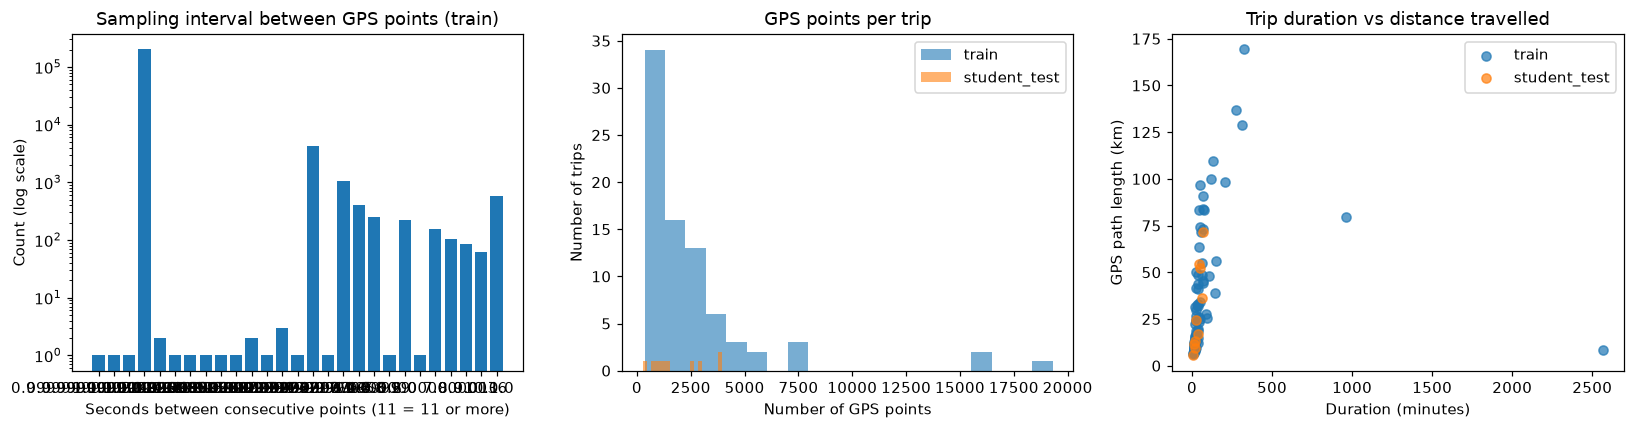

share of steps exactly 1 s (train): 96.5%
trips with a gap > 60 s: 23 of 90


In [4]:
all_dt = pd.concat([pd.DataFrame({'dt': np.diff(load_trip(p, t, with_route=False)['track']['t'].values), 'partition': p})
                    for p in ['train','student_test'] for t in list_trips(p)])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
vc = all_dt[all_dt.partition=='train']['dt'].clip(upper=11).value_counts().sort_index()
ax[0].bar(vc.index.astype(str), vc.values, color='tab:blue'); ax[0].set_yscale('log')
ax[0].set_title('Sampling interval between GPS points (train)')
ax[0].set_xlabel('Seconds between consecutive points (11 = 11 or more)'); ax[0].set_ylabel('Count (log scale)')
for part, col in [('train','tab:blue'), ('student_test','tab:orange')]:
    s = inv[inv.partition==part]
    ax[1].hist(s.n_gps, bins=20, alpha=0.6, color=col, label=part)
    ax[2].scatter(s.duration_min, s.gps_path_km, color=col, label=part, alpha=0.7)
ax[1].set_title('GPS points per trip'); ax[1].set_xlabel('Number of GPS points'); ax[1].set_ylabel('Number of trips'); ax[1].legend()
ax[2].set_title('Trip duration vs distance travelled'); ax[2].set_xlabel('Duration (minutes)'); ax[2].set_ylabel('GPS path length (km)'); ax[2].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/gps_sampling_and_size.png'); plt.show()
print('share of steps exactly 1 s (train): %.1f%%' % (100 * (all_dt[all_dt.partition=='train'].dt == 1).mean()))
print('trips with a gap > 60 s:', (inv.dt_max > 60).sum(), 'of', len(inv))

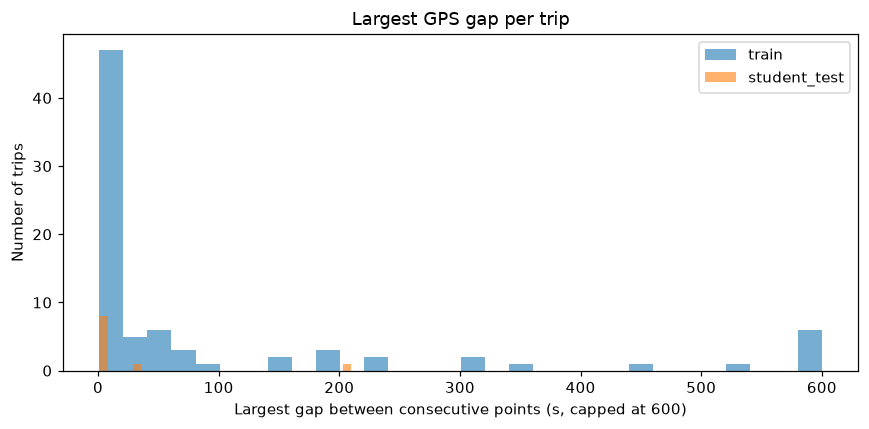

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for part, col in [('train','tab:blue'), ('student_test','tab:orange')]:
    s = inv[inv.partition==part]; ax.hist(s.dt_max.clip(upper=600), bins=30, alpha=.6, color=col, label=part)
ax.set_title('Largest GPS gap per trip'); ax.set_xlabel('Largest gap between consecutive points (s, capped at 600)'); ax.set_ylabel('Number of trips')
ax.legend(); plt.tight_layout(); plt.savefig(f'{OUT}/largest_gap_per_trip.png'); plt.show()

## 3. Where are the trips? Why we convert to metres

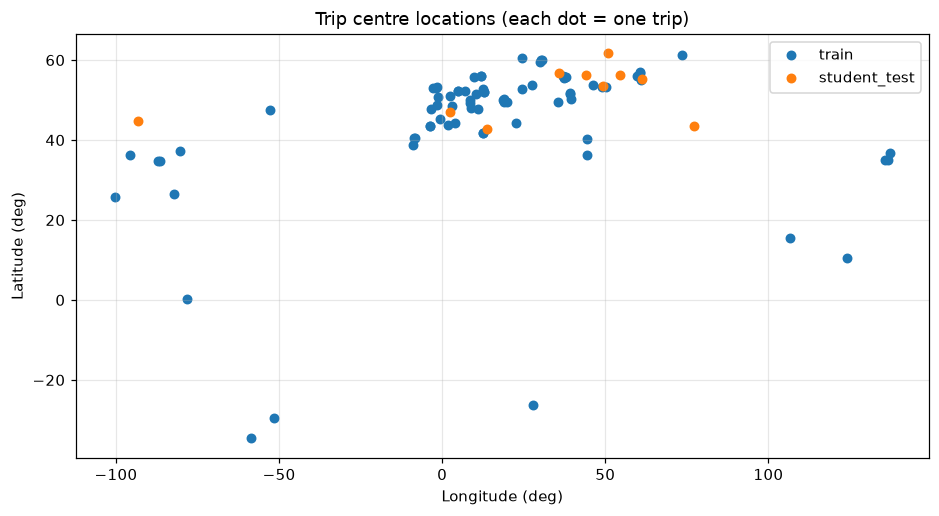

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for part, col in [('train','tab:blue'), ('student_test','tab:orange')]:
    s = inv[inv.partition==part]; ax.scatter(s.lon_c, s.lat_c, color=col, label=part, s=30)
ax.set_title('Trip centre locations (each dot = one trip)'); ax.set_xlabel('Longitude (deg)'); ax.set_ylabel('Latitude (deg)')
ax.legend(); ax.grid(alpha=.3); plt.savefig(f'{OUT}/trip_locations.png'); plt.show()
m = folium.Map(location=[inv.lat_c.mean(), inv.lon_c.mean()], zoom_start=3, tiles='cartodbpositron')
for _, r in inv.iterrows():
    folium.CircleMarker([r.lat_c, r.lon_c], radius=4, color='blue' if r.partition=='train' else 'orange',
        fill=True, popup=f"{r.partition} {r.trip_id}: {r.n_gps} pts").add_to(m)
m.save(f'{MAPS}/01_all_trip_locations.html'); m

Trips are spread over many countries. One degree of longitude is about 72 km at 49°N but about 53 km at 61°N,
so distance in degrees is wrong. We project each trip into local metres and check it against the true
great-circle (haversine) distance:

In [7]:
tr = load_trip('train', '00000001'); t = tr['track']
proj = LocalProjection(t.lon.mean(), t.lat.mean()); P = proj.to_xy(t.lon, t.lat)
d_proj = np.sqrt(((P[1:] - P[:-1]) ** 2).sum(1))
d_true = haversine(t.lon.values[:-1], t.lat.values[:-1], t.lon.values[1:], t.lat.values[1:])
ok = d_true > 1; rel = np.abs(d_proj[ok] - d_true[ok]) / d_true[ok]
print('relative error of local projection vs haversine: median %.4f%%, max %.4f%%' % (100 * np.median(rel), 100 * rel.max()))

relative error of local projection vs haversine: median 0.0136%, max 0.2565%


## 4. Road network size and connectivity

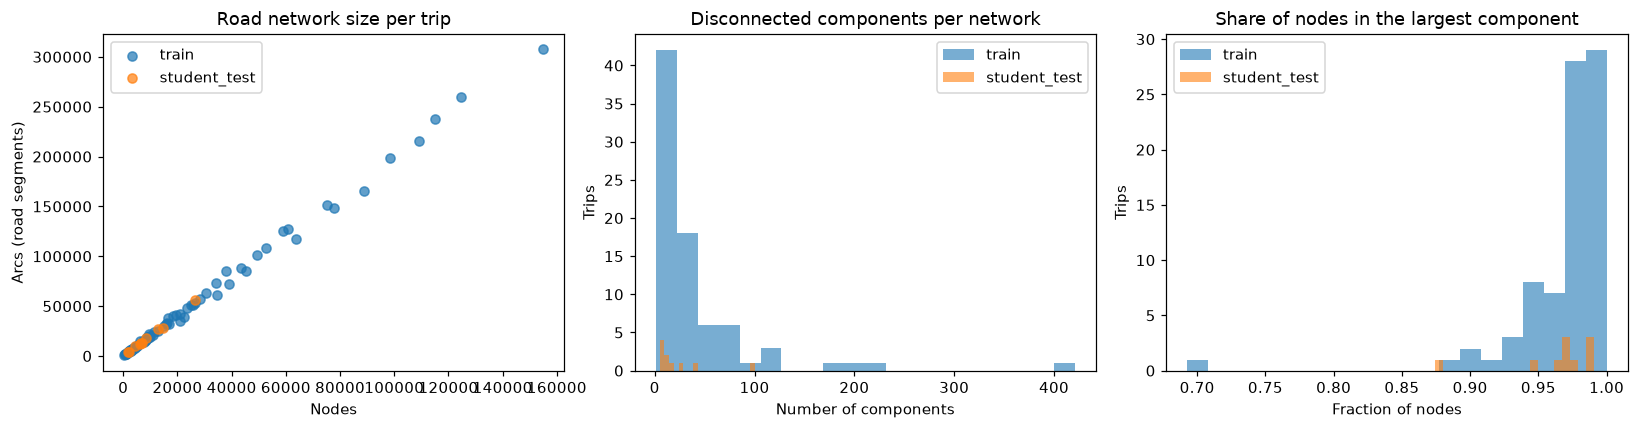

arcs per node (median): 2.03  -> most roads are stored once per direction
isolated nodes total: 0


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for part, col in [('train','tab:blue'), ('student_test','tab:orange')]:
    s = inv[inv.partition==part]
    ax[0].scatter(s.n_nodes, s.n_arcs, color=col, label=part, alpha=.7)
    ax[1].hist(s.components, bins=20, color=col, alpha=.6, label=part)
    ax[2].hist(s.largest_comp_frac, bins=20, color=col, alpha=.6, label=part)
ax[0].set_title('Road network size per trip'); ax[0].set_xlabel('Nodes'); ax[0].set_ylabel('Arcs (road segments)'); ax[0].legend()
ax[1].set_title('Disconnected components per network'); ax[1].set_xlabel('Number of components'); ax[1].set_ylabel('Trips'); ax[1].legend()
ax[2].set_title('Share of nodes in the largest component'); ax[2].set_xlabel('Fraction of nodes'); ax[2].set_ylabel('Trips'); ax[2].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/road_network.png'); plt.show()
print('arcs per node (median): %.2f  -> most roads are stored once per direction' % (inv.n_arcs / inv.n_nodes).median())
print('isolated nodes total:', inv.isolated_nodes.sum())

## 5. Reference route: structure and continuity

route continuity (arc i ends where arc i+1 starts):
              count    mean     std     min  25%  50%  75%  max
partition                                                      
student_test   10.0  0.9997  0.0008  0.9973  1.0  1.0  1.0  1.0
train          80.0  0.9993  0.0025  0.9813  1.0  1.0  1.0  1.0

GPS points per route arc (median) = 5.3


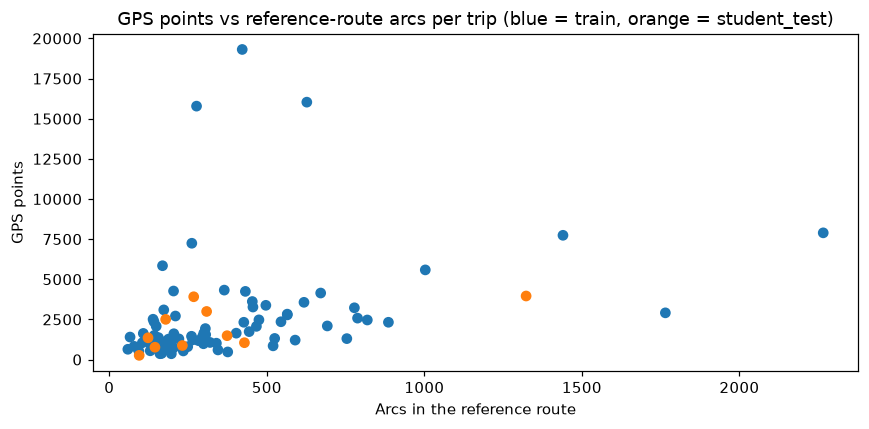

In [9]:
print('route continuity (arc i ends where arc i+1 starts):')
print(inv.groupby('partition').route_continuity.describe().round(4))
print('\nGPS points per route arc (median) = %.1f' % (inv.n_gps / inv.n_route_arcs).median())
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(inv.n_route_arcs, inv.n_gps, c=np.where(inv.partition=='train', 'tab:blue', 'tab:orange'))
ax.set_title('GPS points vs reference-route arcs per trip (blue = train, orange = student_test)')
ax.set_xlabel('Arcs in the reference route'); ax.set_ylabel('GPS points'); plt.tight_layout()
plt.savefig(f'{OUT}/gps_vs_route_arcs.png'); plt.show()

The route is a **chain of arcs**, not one arc per GPS point (about 5 GPS points per arc).
Per-point labels must therefore be built by us — see notebook 02.

## 6. Folium map of one raw trip (GPS points, road network, reference route)

In [10]:
def raw_trip_map(part, tid, out):
    trip = load_trip(part, tid); t = trip['track']; nodes = trip['nodes'].values; arcs = trip['arcs'].values
    m = folium.Map(location=[t.lat.mean(), t.lon.mean()], zoom_start=14, tiles='cartodbpositron')
    from scipy.spatial import cKDTree
    proj = LocalProjection(t.lon.mean(), t.lat.mean())
    tree = cKDTree(proj.to_xy(t.lon.values, t.lat.values))
    d_start, _ = tree.query(proj.to_xy(nodes[arcs[:,0],0], nodes[arcs[:,0],1]))
    inside = d_start < 150          # only road segments within 150 m of the track (keeps the file small)
    g_net = folium.FeatureGroup('Road network within 150 m (grey)')
    for u, v in arcs[inside]:
        folium.PolyLine([(nodes[u,1], nodes[u,0]), (nodes[v,1], nodes[v,0])], color='grey', weight=1, opacity=.5).add_to(g_net)
    g_ref = folium.FeatureGroup('Reference route (green)')
    for a in trip['route']:
        u, v = arcs[a]; folium.PolyLine([(nodes[u,1], nodes[u,0]), (nodes[v,1], nodes[v,0])], color='green', weight=6, opacity=.7).add_to(g_ref)
    g_gps = folium.FeatureGroup('Raw GPS points (blue)')
    for k, r in t.iloc[::3].iterrows():
        folium.CircleMarker([r.lat, r.lon], radius=2, color='blue', fill=True, popup=f'point {k}, t={r.t:.0f}s').add_to(g_gps)
    for g in [g_net, g_ref, g_gps]: g.add_to(m)
    folium.Marker([t.lat.iloc[0], t.lon.iloc[0]], tooltip='Start', icon=folium.Icon(color='green')).add_to(m)
    folium.Marker([t.lat.iloc[-1], t.lon.iloc[-1]], tooltip='End', icon=folium.Icon(color='red')).add_to(m)
    folium.LayerControl(collapsed=False).add_to(m); m.fit_bounds([[t.lat.min(), t.lon.min()], [t.lat.max(), t.lon.max()]])
    m.save(out); return m
raw_trip_map('train', '00000001', f'{MAPS}/01_train_00000001_raw.html')

## 7. Data-quality issues found (and where we handle them)
| Issue | Evidence | Handled in |
|---|---|---|
| Coordinates in degrees, trips in many countries | Section 3 | `geometry.py` local projection (notebook 02) |
| Route is a chain of arcs, not per-point labels | Section 5 | `preprocessing.py` monotonic alignment (notebook 02) |
| Some GPS points far from every route arc | notebook 02 | marked invalid, not scored |
| Long GPS gaps in some trips | Section 2 | `gap` feature; HMM transition grows with the gap (notebook 05) |
| Roads stored once per direction | Section 4 | `heading_diff` feature |
| Each trip has its own network | Section 1 | only relative / metric features, no ids |